In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from models.logPDF_prev import PRIORS

In [2]:
posterior = pd.read_csv("results/simulated/prev_model_beta_rw.csv")
true_parameters = {
    "psir":0.15,
    "i0": np.log(1/1000),
    "pi": 0.85,
    "beta_rw_sd": 0.1,
}

# Summary

* This document shows fitting a SEIR model to some simulated prevalence data.
* Only a single dataset was used, mainly to test that the code is working and produces reasonable results rather than testing the model.
* I ran 100,000 iterations in approx 10 mins on Morricone; the first 80,000 are discarded for burnin (see traceplots).

# Simulation

* A SEIR epidemic with a compartmental structure for prevalence (see previous description).
* 15,000 test results each day (comparable to the ONS CIS) were simulated from a binomial model.
* Duration of latent, infectious, and test positive periods fixed to true values.
* Other parameters (initial growth rate, psir; initial hazard of infection (related to number of initially infected individuals), i0; and proportion of the population without prior immunity, pi) as well as the steps of the random walk which multiplies R0 each week (beta[t]).

Text(0, 0.5, 'Proportion of population')

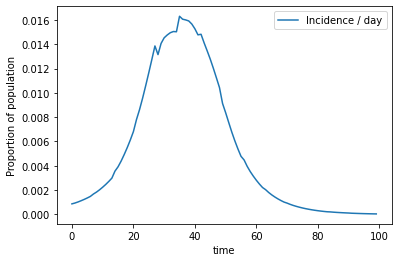

In [3]:
result_simple = pd.read_csv("data/simulated/prev_model_beta_rw.csv")
sns.lineplot(x="time", y="nni", data=result_simple)
plt.legend(labels=["Incidence / day"])
plt.ylabel("Proportion of population")

Text(0, 0.5, 'Proportion of population')

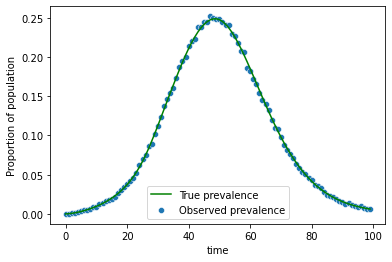

In [4]:
sns.lineplot(x="time", y="prev", data=result_simple, color="green")
sns.scatterplot(x="time", y="observed_prev", data=result_simple)
plt.legend(labels=["True prevalence", "Observed prevalence"])
plt.ylabel("Proportion of population")

# MCMC output

## Full traceplot

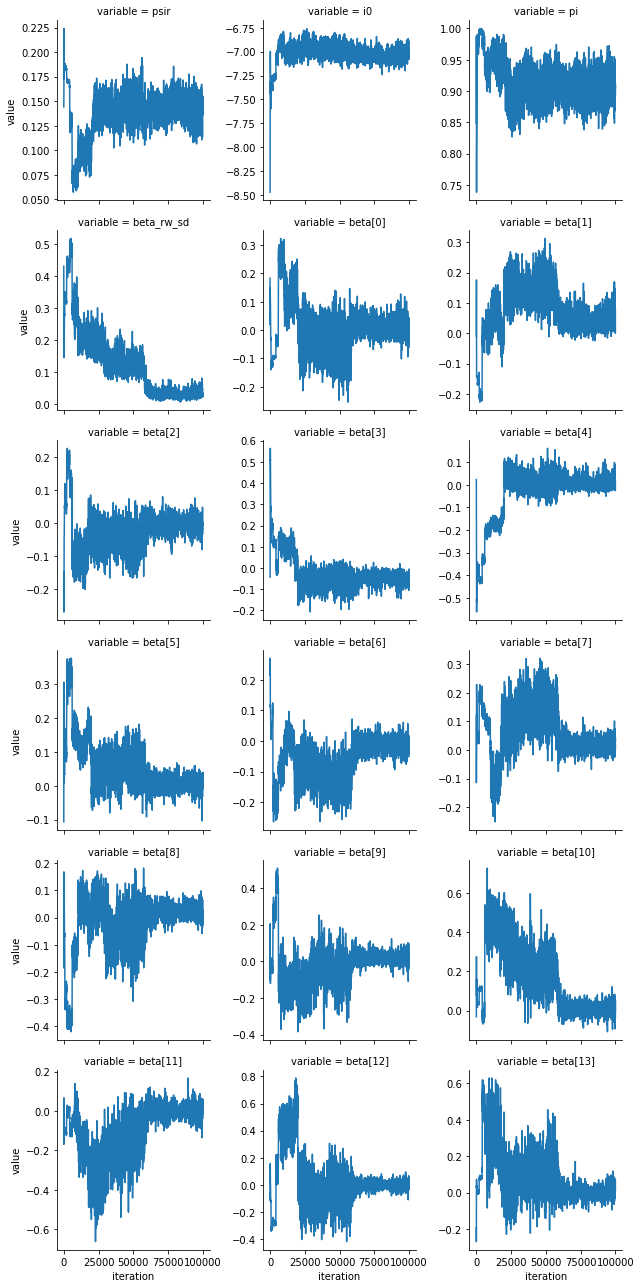

In [5]:
fig = sns.FacetGrid(posterior[::20].melt(id_vars="iteration"), col="variable", col_wrap=3, sharey=False)
fig.map(sns.lineplot, "iteration", "value")

## Post-burnin traceplot

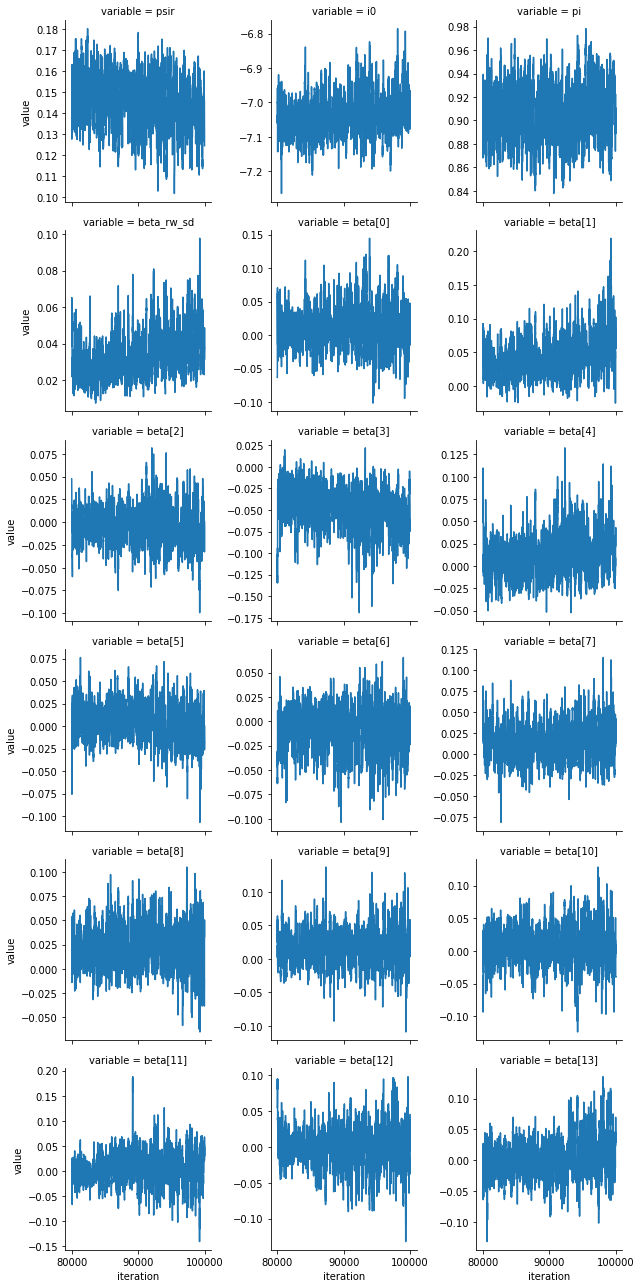

In [6]:
post_burn_thin = posterior[80000:]
fig = sns.FacetGrid(post_burn_thin.melt(id_vars="iteration"), col="variable", col_wrap=3, sharey=False)
fig.map(sns.lineplot, "iteration", "value")

## Posterior density

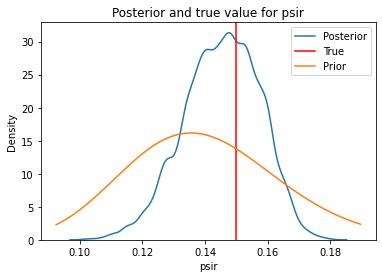

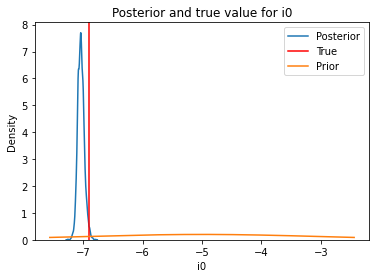

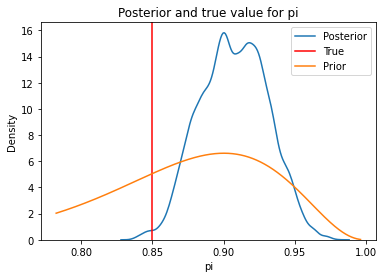

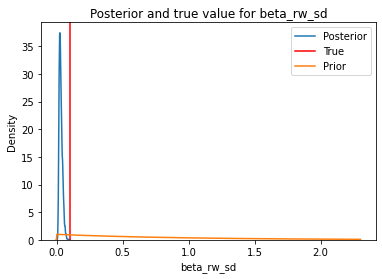

In [9]:
for param, true in true_parameters.items():
    labels = ["Posterior", "True"]
    plt.figure()
    sns.kdeplot(data=post_burn_thin, x=param).set_title("Posterior and true value for {}".format(param))
    plt.axvline(true, color="red")
    if param in PRIORS:
        xmin, xmax = plt.xlim()
        xmin = min(xmin, PRIORS[param].ppf(0.1))
        xmax = max(xmax, PRIORS[param].ppf(0.9))
        xs = np.linspace(xmin, xmax, 1000)
        ys = PRIORS[param].pdf(xs)
        sns.lineplot(x=xs, y=ys)
        labels.append("Prior")
    plt.legend(labels=labels)

## Posterior parameter correlations

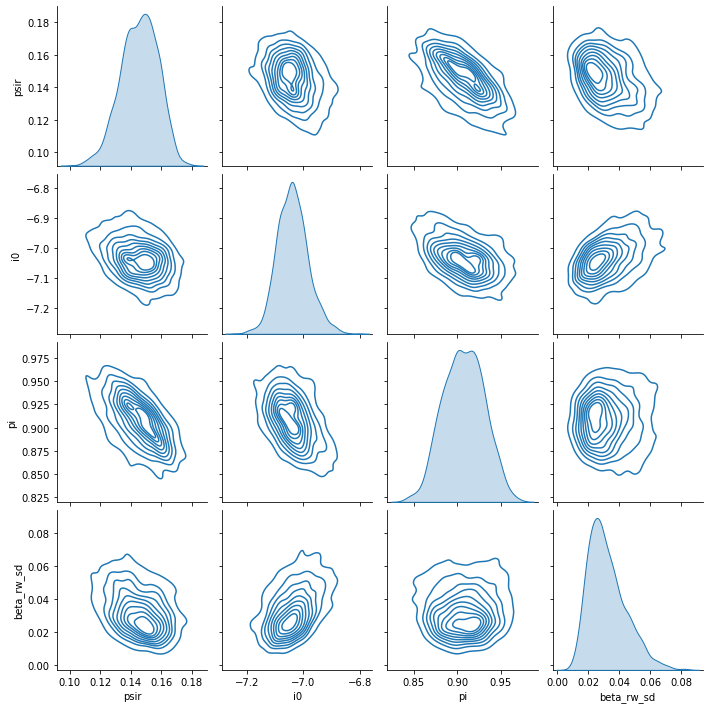

In [10]:
sns.pairplot(post_burn_thin[["psir", "i0", "pi", "beta_rw_sd"]][::10], kind="kde")